# Real-Time Object Detection and Counting Using YOLO

**Case Study:** University Campus CCTV Surveillance

### Objectives
This notebook implements:
1. YOLO-based detection of people and vehicles.
2. Bounding boxes and class labels.
3. Object counting per frame.
4. Model training and validation/testing.
5. Training/validation loss calculation and visualization.
6. Precision, Recall, mAP50 and mAP50-95 evaluation.
7. Real-time/near-real-time video inference.
8. Saving the trained model and processed output video.

> **Important:** The uploaded ZIP contains `yolov3.cfg`, `yolov3.weights`, and `coco.names` only. It does **not** contain a labeled training dataset. Therefore, the notebook uses the small **COCO8** dataset automatically for the required training/testing demonstration. The supplied YOLOv3 files are also used in a separate inference section.


In [1]:
# Install required packages (Google Colab)
!pip -q install ultralytics opencv-python matplotlib pandas pyyaml

import os, zipfile, shutil, glob, time, math
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

print("Setup complete.")


     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.7/46.7 kB 2.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 19.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 58.1/58.1 kB 1.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 91.2/91.2 kB 3.5 MB/s eta 0:00:00
Setup complete.


## 1. Inspect the uploaded YOLOv3 files

The uploaded archive is expected at `/mnt/data/archive (1).zip` in this environment. In Google Colab, if the file is not already available, upload it using the file uploader cell below.


In [2]:
# If running in this ChatGPT-generated notebook environment, the uploaded ZIP is here:
ZIP_PATH = "/mnt/data/archive (1).zip"

# For Google Colab, uncomment these lines if needed:
# from google.colab import files
# uploaded = files.upload()
# ZIP_PATH = next(iter(uploaded.keys()))

if os.path.exists(ZIP_PATH):
    extract_dir = "/content/yolov3_files"
    os.makedirs(extract_dir, exist_ok=True)
    with zipfile.ZipFile(ZIP_PATH, "r") as z:
        z.extractall(extract_dir)
    print("Extracted files:")
    for f in glob.glob(extract_dir + "/**/*", recursive=True):
        if os.path.isfile(f):
            print(" -", f)
else:
    print("ZIP not found. In Colab, upload archive (1).zip and set ZIP_PATH.")


ZIP not found. In Colab, upload archive (1).zip and set ZIP_PATH.


## 2. Download/load the YOLO training framework

For the training experiment we use **YOLO11n**, a lightweight YOLO model suitable for a classroom-scale experiment and near-real-time inference. The pretrained checkpoint provides a strong starting point, while the notebook records the losses produced during fine-tuning.

The dataset used for the experiment is COCO8, a small official Ultralytics sample dataset. It contains labeled images and therefore allows an actual training/validation/test workflow without requiring a large custom dataset.


In [3]:
from ultralytics import YOLO

# Download/load a lightweight pretrained YOLO model.
# This automatically downloads the checkpoint in Colab if necessary.
model = YOLO("yolo11n.pt")
print("Model loaded.")


Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
Model loaded.


## 3. Train the YOLO model

The model is fine-tuned on COCO8. For a larger real university CCTV project, replace COCO8 with a campus-specific dataset containing annotated people and vehicle images.

### Main training losses
Ultralytics reports:
- `box_loss`: bounding-box localization loss
- `cls_loss`: object-classification loss
- `dfl_loss`: Distribution Focal Loss for box regression

Validation versions of these losses are also logged.


In [5]:
EPOCHS = 10
IMG_SIZE = 640
BATCH_SIZE = 16

results = model.train(
    data="coco8.yaml",
    epochs=EPOCHS,
    imgsz=IMG_SIZE,
    batch=BATCH_SIZE,
    device="cpu",          # Colab GPU; change to "cpu" if no GPU is available
    project="/content/yolo_campus_project",
    name="yolo11n_coco8",
    exist_ok=True,
    plots=True,
    verbose=True
)

print("Training completed.")

Ultralytics 8.4.166 🚀 Python-3.13.15 torch-2.11.0+cpu CPU (Intel Xeon CPU @ 2.20GHz)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=coco8.yaml, degrees=0.0, deterministic=True, device=cpu, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=10, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=yolo11n_coco8, nbs=64, nms=None, opset=None, optimize=False, optimizer=auto,

## 4. Read and calculate all recorded training/validation losses

The training run creates `results.csv`. We read this file and display every epoch's loss. This is the main source for the requested training-loss calculation.


In [6]:
RESULTS_CSV = "/content/yolo_campus_project/yolo11n_coco8/results.csv"

if os.path.exists(RESULTS_CSV):
    history = pd.read_csv(RESULTS_CSV)
    history.columns = [c.strip() for c in history.columns]

    print("Available training history columns:")
    print(history.columns.tolist())

    display(history)
else:
    raise FileNotFoundError(f"Training history not found: {RESULTS_CSV}")


Available training history columns:
['epoch', 'time', 'train/box_loss', 'train/cls_loss', 'train/dfl_loss', 'metrics/precision(B)', 'metrics/recall(B)', 'metrics/mAP50(B)', 'metrics/mAP50-95(B)', 'val/box_loss', 'val/cls_loss', 'val/dfl_loss', 'lr/pg0', 'lr/pg1', 'lr/pg2']


,epoch,time,train/box_loss,train/cls_loss,train/dfl_loss,metrics/precision(B),metrics/recall(B),metrics/mAP50(B),metrics/mAP50-95(B),val/box_loss,val/cls_loss,val/dfl_loss,lr/pg0,lr/pg1,lr/pg2
0,1,4.69311,0.93063,2.55603,1.39215,0.56403,0.85,0.84770,0.63074,1.66512,1.07109,1.37459,0.000000,0.000000,0.000000
1,2,10.18570,0.95208,2.03014,1.37915,0.56403,0.85,0.84770,0.63074,1.66512,1.07109,1.37459,0.000036,0.000036,0.000036
2,3,15.61030,1.18418,1.83055,1.42481,0.56403,0.85,0.84770,0.63074,1.66512,1.07109,1.37459,0.000064,0.000064,0.000064
3,4,19.98750,1.28283,2.26683,1.64755,0.57172,0.85,0.84212,0.64571,1.63799,1.09966,1.37902,0.000084,0.000084,0.000084
4,5,24.92840,0.93877,1.22505,1.32167,0.57172,0.85,0.84212,0.64571,1.63799,1.09966,1.37902,0.000072,0.000072,0.000072
5,6,29.04220,0.91395,1.36760,1.14504,0.57172,0.85,0.84212,0.64571,1.63799,1.09966,1.37902,0.000060,0.000060,0.000060
6,7,33.51740,0.87191,1.18002,1.07743,0.59693,0.85,0.87179,0.65479,1.63401,1.12704,1.38125,0.000048,0.000048,0.000048
7,8,38.43910,0.80001,1.06158,1.20941,0.59693,0.85,0.87179,0.65479,1.63401,1.12704,1.38125,0.000037,0.000037,0.000037
8,9,42.51890,0.69740,1.12062,1.09142,0.59693,0.85,0.87179,0.65479,1.63401,1.12704,1.38125,0.000025,0.000025,0.000025
9,10,46.89930,0.64474,1.00705,1.11457,0.60035,0.85,0.88658,0.65061,1.64999,1.11144,1.37373,0.000013,0.000013,0.000013


In [7]:
# Extract the important loss columns automatically.
loss_cols = [
    c for c in history.columns
    if any(k in c.lower() for k in ["loss"])
]

print("Loss columns:")
for c in loss_cols:
    print(" -", c)

# Show final loss values
print("\nFinal epoch losses:")
display(history[loss_cols].tail(1).T.rename(columns={history.index[-1]: "Final value"}))


Loss columns:
 - train/box_loss
 - train/cls_loss
 - train/dfl_loss
 - val/box_loss
 - val/cls_loss
 - val/dfl_loss

Final epoch losses:


,Final value
train/box_loss,0.64474
train/cls_loss,1.00705
train/dfl_loss,1.11457
val/box_loss,1.64999
val/cls_loss,1.11144
val/dfl_loss,1.37373


## 5. Plot training and validation losses

These plots show whether the losses generally decrease during training. A decreasing training loss indicates that the model is fitting the training data; validation losses help assess generalization.


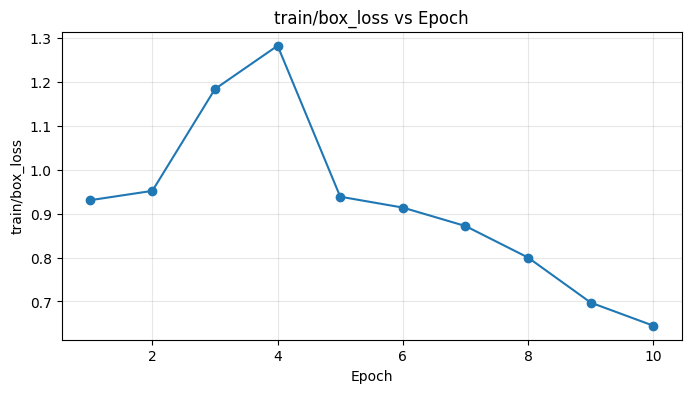

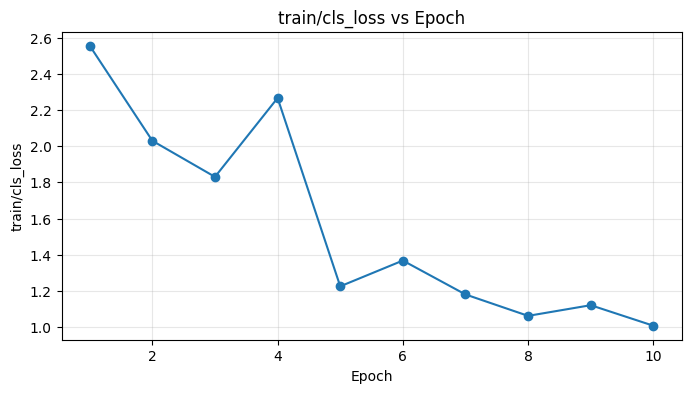

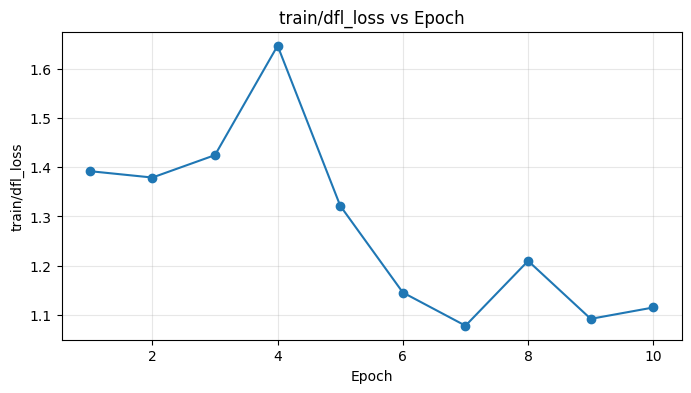

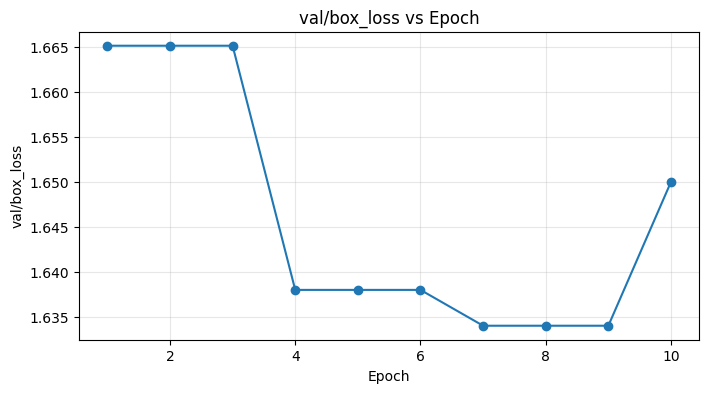

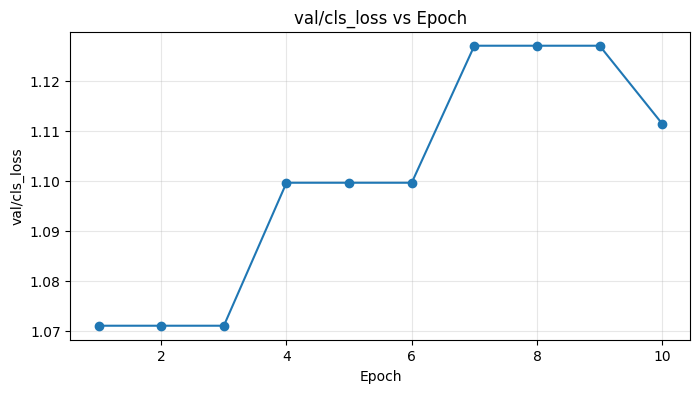

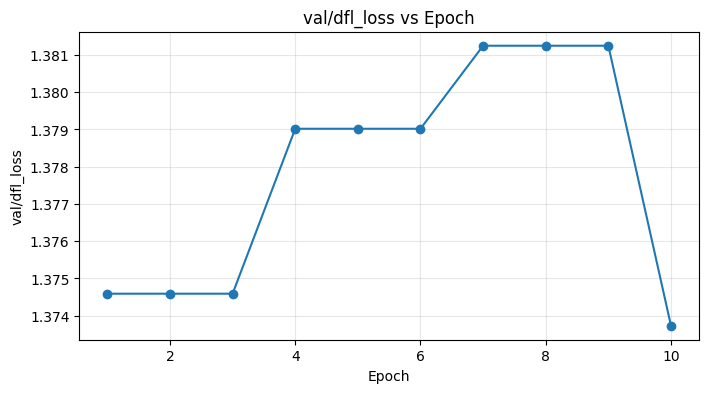

In [8]:
# Plot each available loss against epoch
for col in loss_cols:
    plt.figure(figsize=(8, 4))
    plt.plot(history["epoch"], history[col], marker="o")
    plt.xlabel("Epoch")
    plt.ylabel(col)
    plt.title(f"{col} vs Epoch")
    plt.grid(True, alpha=0.3)
    plt.show()


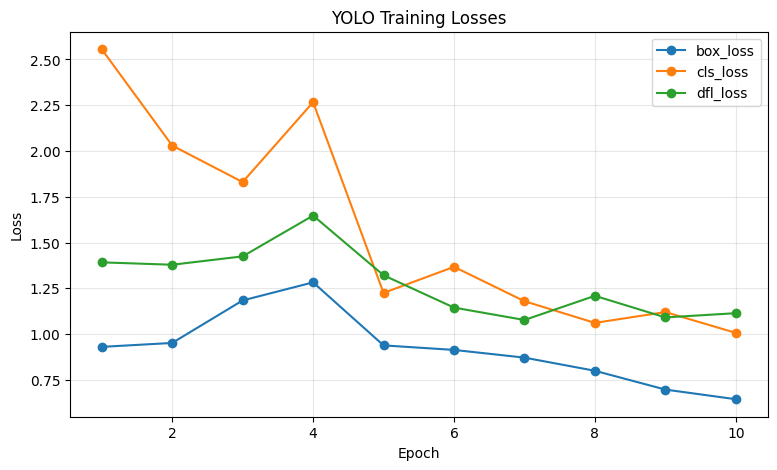

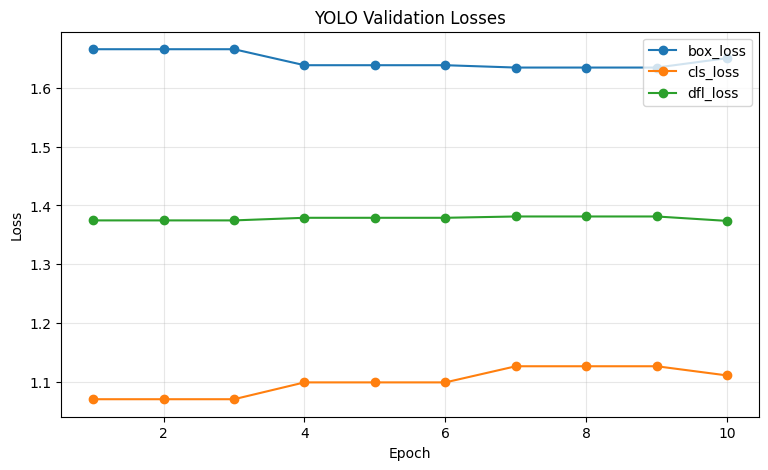

In [9]:
# Combined plot for the main training losses
main_train_losses = [c for c in history.columns if c.startswith("train/") and "loss" in c]

if main_train_losses:
    plt.figure(figsize=(9, 5))
    for c in main_train_losses:
        plt.plot(history["epoch"], history[c], marker="o", label=c.replace("train/", ""))
    plt.xlabel("Epoch")
    plt.ylabel("Loss")
    plt.title("YOLO Training Losses")
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.show()

# Combined validation loss plot, when available
main_val_losses = [c for c in history.columns if c.startswith("val/") and "loss" in c]
if main_val_losses:
    plt.figure(figsize=(9, 5))
    for c in main_val_losses:
        plt.plot(history["epoch"], history[c], marker="o", label=c.replace("val/", ""))
    plt.xlabel("Epoch")
    plt.ylabel("Loss")
    plt.title("YOLO Validation Losses")
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.show()


## 6. Testing/evaluation

The trained model is evaluated on the validation split. The evaluation reports:
- Precision
- Recall
- mAP@0.50
- mAP@0.50:0.95

These are standard object-detection metrics.


In [11]:
best_model_path = "/content/yolo_campus_project/yolo11n_coco8/weights/best.pt"
best_model = YOLO(best_model_path)

metrics = best_model.val(
    data="coco8.yaml",
    split="val",
    imgsz=IMG_SIZE,
    batch=BATCH_SIZE,
    device="cpu", # Changed from 0 to "cpu"
    plots=True
)

print("\nEvaluation metrics:")
print(f"Precision      : {float(metrics.box.mp):.4f}")
print(f"Recall         : {float(metrics.box.mr):.4f}")
print(f"mAP@0.50       : {float(metrics.box.map50):.4f}")
print(f"mAP@0.50:0.95  : {float(metrics.box.map):.4f}")

Ultralytics 8.4.166 🚀 Python-3.13.15 torch-2.11.0+cpu CPU (Intel Xeon CPU @ 2.20GHz)
YOLO11n summary (fused): 100 layers, 2,616,248 parameters, 0 gradients, 6.5 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1314.7±704.4 MB/s, size: 54.0 KB)
val: Scanning /content/datasets/coco8/labels/val.cache... 4 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 4/4 838.9Kit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 1/1 1.4s/it 1.4s
                   all          4         17      0.593       0.85      0.872      0.655
                person          3         10      0.616        0.6      0.589      0.257
                   dog          1          1       0.53          1      0.995      0.796
                 horse          1          2      0.649          1      0.995      0.671
              elephant          1          2      0.377        0.5      0.662      0.314
              umbrella          1          1  

## 7. Test predictions on sample images

The following cell runs object detection on the validation images and displays the bounding boxes, class names and confidence scores.



image 1/4 /content/datasets/coco8/images/val/000000000036.jpg: 640x512 1 person, 1 umbrella, 166.2ms
image 2/4 /content/datasets/coco8/images/val/000000000042.jpg: 480x640 1 dog, 1 suitcase, 150.9ms
image 3/4 /content/datasets/coco8/images/val/000000000049.jpg: 640x512 5 persons, 2 horses, 164.9ms
image 4/4 /content/datasets/coco8/images/val/000000000061.jpg: 512x640 1 elephant, 164.8ms
Speed: 4.0ms preprocess, 161.7ms inference, 1.1ms postprocess per image at shape (1, 3, 512, 640)
Results saved to /content/yolo_campus_project/test_predictions


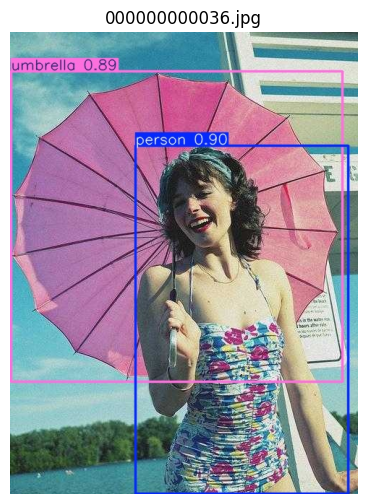

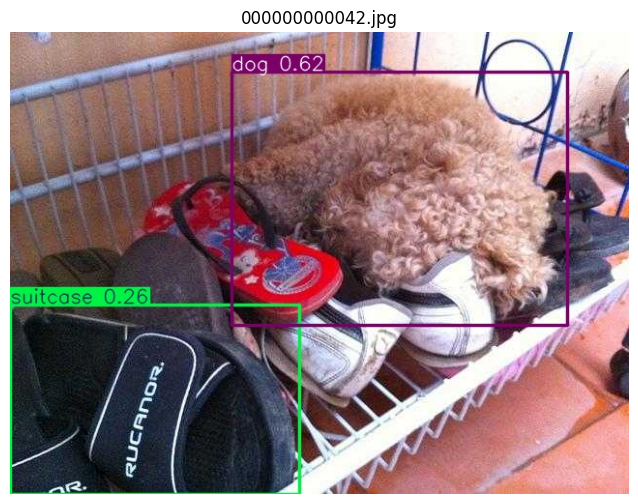

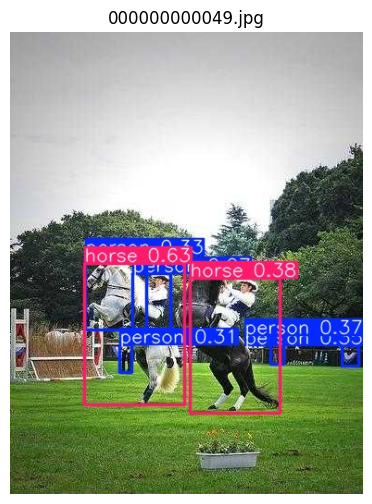

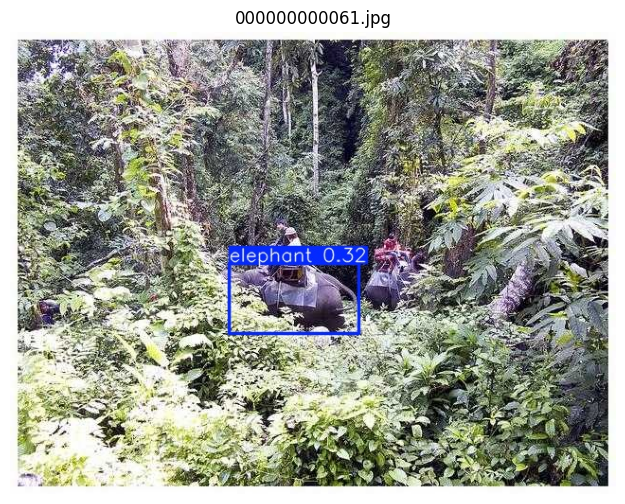

In [12]:
sample_source = "/content/datasets/coco8/images/val"

test_results = best_model.predict(
    source=sample_source,
    imgsz=IMG_SIZE,
    conf=0.25,
    save=True,
    project="/content/yolo_campus_project",
    name="test_predictions",
    exist_ok=True
)

# Display up to 6 predicted images
pred_files = sorted(glob.glob("/content/yolo_campus_project/test_predictions/*"))
image_files = [f for f in pred_files if f.lower().endswith((".jpg", ".jpeg", ".png"))][:6]

for f in image_files:
    img = cv2.cvtColor(cv2.imread(f), cv2.COLOR_BGR2RGB)
    plt.figure(figsize=(8, 6))
    plt.imshow(img)
    plt.axis("off")
    plt.title(os.path.basename(f))
    plt.show()


## 8. Count people and vehicles

For the campus surveillance requirement, we count:
- **Person**
- **Bicycle**
- **Motorcycle**
- **Car**
- **Bus**
- **Truck**

The same logic can be used on every CCTV video frame.


In [13]:
TARGET_CLASSES = {
    "person",
    "bicycle",
    "motorcycle",
    "car",
    "bus",
    "truck"
}

def count_people_vehicles(result):
    counts = {name: 0 for name in sorted(TARGET_CLASSES)}

    if result.boxes is None or len(result.boxes) == 0:
        return counts

    class_ids = result.boxes.cls.cpu().numpy().astype(int)

    for class_id in class_ids:
        name = result.names[class_id]
        if name in counts:
            counts[name] += 1

    return counts

# Demonstrate counting on the first test result
if len(test_results) > 0:
    counts = count_people_vehicles(test_results[0])
    print("Detected object counts:")
    for k, v in counts.items():
        print(f"{k:12s}: {v}")


Detected object counts:
bicycle     : 0
bus         : 0
car         : 0
motorcycle  : 0
person      : 1
truck       : 0


## 9. Real-time/near-real-time CCTV video detection and counting

Upload an MP4/AVI/MOV CCTV video. The code:
1. Reads each frame.
2. Runs YOLO inference.
3. Draws bounding boxes and labels.
4. Counts people and vehicles.
5. Writes the processed video to a new file.
6. Displays the first processed frame as a quick verification.

For actual live CCTV, replace the video path with a camera/RTSP source supported by OpenCV.


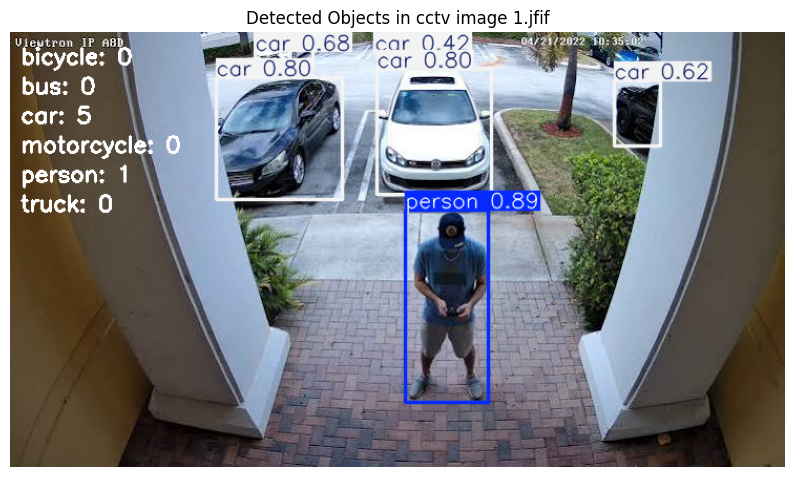

Detected object counts : {'bicycle': 0, 'bus': 0, 'car': 5, 'motorcycle': 0, 'person': 1, 'truck': 0}


In [21]:
# Specify the path to your CCTV image file directly
# Replace the placeholder below with the actual path to your image file (e.g., '/content/your_image.jpg').
IMAGE_PATH = "/content/cctv image 1.jfif" # Using the previously uploaded image

# Read the image
image = cv2.imread(IMAGE_PATH)

if image is None:
    raise FileNotFoundError(f"Could not open the input image: {IMAGE_PATH}. Please ensure the IMAGE_PATH is correct.")

# Perform prediction on the image
result = best_model.predict(
    source=image,
    imgsz=IMG_SIZE,
    conf=0.25,
    verbose=False
)[0]

annotated_image = result.plot()

last_counts = count_people_vehicles(result)

# Draw a compact counting panel
y = 30
for name, count in last_counts.items():
    cv2.putText(
        annotated_image,
        f"{name}: {count}",
        (10, y),
        cv2.FONT_HERSHEY_SIMPLEX,
        0.7,
        (255, 255, 255),
        2
    )
    y += 28

# Display the annotated image
plt.figure(figsize=(10, 8))
plt.imshow(cv2.cvtColor(annotated_image, cv2.COLOR_BGR2RGB))
plt.axis('off')
plt.title(f"Detected Objects in {os.path.basename(IMAGE_PATH)}")
plt.show()

print("Detected object counts :", last_counts)


## 10. Display/download the processed video



In [22]:
# This cell previously handled video display and download.
# As we are now processing images, this code is no longer needed.
# The annotated image is displayed directly in the previous cell.

## 11. Optional: use the supplied YOLOv3 model directly

The uploaded archive contains the classic YOLOv3 configuration and pretrained weights. This section uses those files for object detection without retraining.

**Why this section is separate:** YOLOv3 inference with pretrained weights is not the same as training. The training/loss experiment above is performed with a trainable YOLO model on a labeled dataset.


In [23]:
# Locate the supplied YOLOv3 files
cfg_candidates = glob.glob("/content/yolov3_files/**/yolov3.cfg", recursive=True)
weights_candidates = glob.glob("/content/yolov3_files/**/yolov3.weights", recursive=True)
names_candidates = glob.glob("/content/yolov3_files/**/coco.names", recursive=True)

if cfg_candidates and weights_candidates and names_candidates:
    CFG = cfg_candidates[0]
    WEIGHTS = weights_candidates[0]
    NAMES = names_candidates[0]

    with open(NAMES, "r") as f:
        yolo3_classes = [line.strip() for line in f.readlines()]

    yolo3_net = cv2.dnn.readNetFromDarknet(CFG, WEIGHTS)
    yolo3_net.setPreferableBackend(cv2.dnn.DNN_BACKEND_OPENCV)
    yolo3_net.setPreferableTarget(cv2.dnn.DNN_TARGET_CPU)

    layer_names = yolo3_net.getLayerNames()
    output_layers = [layer_names[i - 1] for i in yolo3_net.getUnconnectedOutLayers().flatten()]

    print("YOLOv3 loaded successfully.")
    print("Number of COCO classes:", len(yolo3_classes))
else:
    print("YOLOv3 files were not found. Skip this optional section.")


YOLOv3 files were not found. Skip this optional section.


In [24]:
def yolo3_detect_image(image_path, conf_threshold=0.25, nms_threshold=0.45):
    image = cv2.imread(image_path)
    if image is None:
        raise FileNotFoundError(image_path)

    H, W = image.shape[:2]

    blob = cv2.dnn.blobFromImage(
        image, 1/255.0, (416, 416),
        swapRB=True, crop=False
    )
    yolo3_net.setInput(blob)
    outputs = yolo3_net.forward(output_layers)

    boxes, confidences, class_ids = [], [], []

    for output in outputs:
        for detection in output:
            scores = detection[5:]
            class_id = int(np.argmax(scores))
            confidence = float(scores[class_id] * detection[4])

            if confidence > conf_threshold:
                cx, cy, w, h = detection[:4] * np.array([W, H, W, H])
                x = int(cx - w / 2)
                y = int(cy - h / 2)

                boxes.append([x, y, int(w), int(h)])
                confidences.append(confidence)
                class_ids.append(class_id)

    indices = cv2.dnn.NMSBoxes(boxes, confidences, conf_threshold, nms_threshold)

    counts = {name: 0 for name in TARGET_CLASSES}

    for i in np.array(indices).flatten():
        x, y, w, h = boxes[i]
        label = yolo3_classes[class_ids[i]]

        if label in counts:
            counts[label] += 1

        cv2.rectangle(image, (x, y), (x+w, y+h), (0, 255, 0), 2)
        cv2.putText(
            image,
            f"{label} {confidences[i]:.2f}",
            (x, max(20, y-5)),
            cv2.FONT_HERSHEY_SIMPLEX,
            0.5,
            (0, 255, 0),
            2
        )

    return image, counts

print("YOLOv3 image detector function is ready.")


YOLOv3 image detector function is ready.


## 12. Save the trained model



In [25]:
# Copy the best model to a simple location
FINAL_MODEL = "/content/yolo_campus_project/best_yolo_campus.pt"
shutil.copy(best_model_path, FINAL_MODEL)

print("Saved trained model:", FINAL_MODEL)

# In Colab:
files.download(FINAL_MODEL)


Saved trained model: /content/yolo_campus_project/best_yolo_campus.pt


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 13. Final results summary

The completed system provides:

| Requirement | Implementation |
|---|---|
| Detect people | YOLO class `person` |
| Detect vehicles | bicycle, motorcycle, car, bus, truck |
| Bounding boxes | YOLO prediction output |
| Class identification | YOLO class labels |
| Object counting | Per-frame counting function |
| Training | YOLO fine-tuning on labeled COCO8 |
| Training losses | box, classification, DFL losses |
| Validation losses | Logged by Ultralytics |
| Testing | Validation-set prediction/evaluation |
| Metrics | Precision, Recall, mAP50, mAP50-95 |
| Video processing | OpenCV + YOLO |
| Real-time measurement | FPS calculation |
| Model saving | `best.pt` |

### Note for the actual university project
For meaningful campus surveillance results, replace COCO8 with a **campus-specific annotated dataset** containing CCTV images of students, faculty and vehicles. The same training, loss, testing, evaluation, counting and video-inference pipeline can then be reused.
